# CS 584-A: Natural Language Processing - Homework 2
**Sentiment analysis on Amazon product reviews with RNN (LSTM) and CNN**

## **Student:** Mandar Sanju Bavdane &nbsp;&nbsp; **CWID:** 20041513

---
### Task definition (stated up front, as the assignment requires)
* **HW1 task:** Binary Classification. **Therefore HW2 task (as instructed):** **Multi-class (5-class) Sentiment Classification.**


* **How the class labels were prepared** (from the 1-5 star `overall` rating):

| `overall` rating | HW2 class label |
|---|---|
| 1 star | 0 |
| 2 stars | 1 |
| 3 stars | 2 (**neutral reviews are now kept**: they were discarded in HW1's binary task) |
| 4 stars | 3 |
| 5 stars | 4 |

* **Data preprocessing:** exactly the same steps as HW1 (drop missing text, lowercase, remove punctuation and numbers, whitespace tokenization, NLTK stop-word removal).
* **Data split:** the same **80 / 10 / 10** --> train / validation(dev) / test split and seed same to HW1. Every review that was in a HW1 partition stays in the same partition; the 3-star reviews (not present in HW1) are split 80/10/10 with the same seed and added to the three partitions.
* **Models:**
- (1) 2-layer **LSTM**, random word embeddings learned during training, optimised with **SGD**;
- (2) **CNN** (Kim-2014 style), **GloVe-initialised** embeddings (the same `glove-wiki-gigaword-200` as HW1) that are fine-tuned, optimised with **mini-batch gradient descent, batch size 20**.
* **Model selection:** the epoch with the best **validation macro-F1** is kept; the final numbers are computed **once** on the untouched test set.

## 0. Setup

In [4]:
import os, re, string, random, copy, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, log_loss, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)


SEED = 42                      # same global seed as HW1 -> same data split
random.seed(SEED)
np.random.seed(SEED)

sns.set_style("whitegrid")     # consistent plot style
plt.rcParams["figure.dpi"] = 110

nltk.download("stopwords", quiet=True)   # one-off download of the stop-word list
print("Setup complete.")

Setup complete.


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

def set_seed(seed=SEED):
    """Fix every random number generator so that a run can be reproduced."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True     # deterministic GPU kernels
    torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # use the GPU when available
print("PyTorch version:", torch.__version__, "| device:", device)

PyTorch version: 2.14.1+cu130 | device: cuda


# 1. Data preparation
## 1) Data preprocessing

**Step A - Load the dataset.** Read the CSV, look at its size and check for missing values (same as HW1).

In [6]:
# The file path used in HW1 (Google Colab). If the file is not there, fall back to the current folder.
DATA_PATH = '/content/amazon_reviews.csv'
if not os.path.exists(DATA_PATH):
    DATA_PATH = 'amazon_reviews.csv'

df_raw = pd.read_csv(DATA_PATH)    # Load data
print("Shape of raw data:", df_raw.shape)
print("\nMissing values per column:\n", df_raw.isna().sum())
print("\n\nFirst five rows:")
df_raw.head()

Shape of raw data: (4915, 2)

Missing values per column:
 overall       0
reviewText    1
dtype: int64


First five rows:


,overall,reviewText
0,4,No issues.
1,5,"Purchased this for my device, it worked as adv..."
2,4,it works as expected. I should have sprung for...
3,5,This think has worked out great.Had a diff. br...
4,5,"Bought it with Retail Packaging, arrived legit..."


**Step B - Clean and label.**
* The review without text (`NaN`) is dropped.
* The original 5-star distribution is plotted and is **strongly imbalanced toward 5 stars**, and 2-star reviews are very rare. This matters for the multi-class task.
* **Multi-class labels:** `label = overall - 1`, i.e. ratings 1-5 become classes 0-4. Also only difference if compared to HW1 is that the neutral 3-star reviews are **kept** as their own class.
* A helper column `binary_label` (4-5 -> 1, 1-2 -> 0) is also created, **only** for the reference purpose

Rows after dropping missing text: 4914 (removed 1)



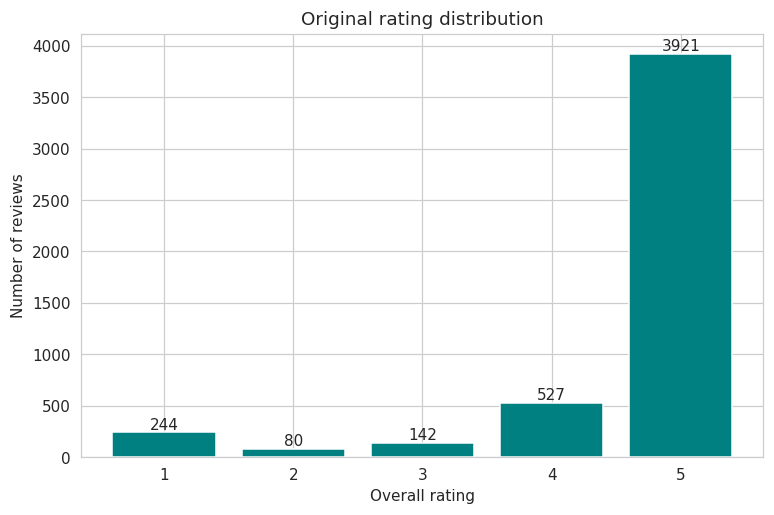


Multi-class label counts (0 = 1-star ... 4 = 5-star):
label
0     244
1      80
2     142
3     527
4    3921
Name: count, dtype: int64


In [7]:
# 1) Drop rows without review text
df = df_raw.dropna(subset=["reviewText"]).copy()
print(f"Rows after dropping missing text: {len(df)} (removed {len(df_raw) - len(df)})\n")

# 2) Plot the original ratings
rating_counts = df["overall"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(rating_counts.index.astype(str), rating_counts.values, color="teal")
ax.bar_label(bars)
ax.set_xlabel("Overall rating"); ax.set_ylabel("Number of reviews")
ax.set_title("Original rating distribution")
plt.show()

# 3) Multi-class labels: rating 1-5 -> class 0 to 4 (3-star reviews are kept as class 2)
df["label"] = df["overall"].astype(int) - 1
CLASS_NAMES = ["1-star", "2-star", "3-star", "4-star", "5-star"]
NUM_CLASSES = len(CLASS_NAMES)

# Helper used ONLY to reproduce the HW1 data split (never used as a training target)
df["binary_label"] = (df["overall"] >= 4).astype(int)

print("\nMulti-class label counts (0 = 1-star ... 4 = 5-star):")
print(df["label"].value_counts().sort_index())

**Step C - Text preprocessing (similar to HW1).**

1. **lowercase** everything
2. **Remove punctuation** - apostrophes are deleted (e.g. `don't` -> `dont`), every other punctuation mark is replaced by a space (e.g. `well-made` -> `well made`)
3. **Remove numbers**
4. **Tokenize** by whitespace
5. **Remove stop-words** using NLTK's English list

`Note`: NLTK's list also removes negations such as *not* / *no* (same limitation as in HW1).

In [8]:
STOPWORDS = set(stopwords.words("english"))
STOPWORDS |= {w.replace("'", "") for w in STOPWORDS}          # e.g. "don't" -> "dont"

PUNCT_TO_SPACE = str.maketrans({c: " " for c in string.punctuation if c != "'"})

def preprocess(text):
    """Raw review string -> list of cleaned tokens."""
    text = text.lower()                                        # lowercase
    text = text.replace("'", "").replace("’", "")              # curly apostrophes
    text = text.translate(PUNCT_TO_SPACE)                      # remove punctuation
    text = re.sub(r"\d+", " ", text)                           # remove numbers
    tokens = text.split()                                      # tokenize on whitespace
    return [t for t in tokens if t not in STOPWORDS]           # remove stopwords

df["tokens"] = df["reviewText"].apply(preprocess)

# Before & After
example = df.iloc[3]
print("RAW   :", example["reviewText"][:200])
print("TOKENS:", example["tokens"][:25])

# Dropping the reviews that became empty after cleaning
empty_mask = df["tokens"].str.len() == 0
print(f"\nEmpty reviews removed: {int(empty_mask.sum())} (by rating: {df.loc[empty_mask, 'overall'].value_counts().to_dict()})")
df = df[~empty_mask].reset_index(drop=True)
print(f"Final number of reviews: {len(df)}")

RAW   : This think has worked out great.Had a diff. bran 64gb card and if went south after 3 months.This one has held up pretty well since I had my S3, now on my Note3.*** update 3/21/14I've had this for a fe
TOKENS: ['think', 'worked', 'great', 'diff', 'bran', 'gb', 'card', 'went', 'south', 'months', 'one', 'held', 'pretty', 'since', 'note', 'update', 'months', 'zero', 'issues', 'since', 'transferred', 'note', 'note', 'card', 'reliable']

Empty reviews removed: 0 (by rating: {})
Final number of reviews: 4914


## 2) Data split (same as HW1)

HW1 split the **non-neutral** reviews with two calls of `train_test_split` (80/20 and then 20 -> 10/10), stratified by the binary label with `random_state=42`. Here the **identical code on the identical (non-neutral) rows** is run first, so each of those reviews lands in the same partition as in HW1 (the sizes 3817 / 477 / 478 are re-printed as a check). The neutral 3-star reviews, which did not exist in HW1, are then split 80/10/10 with the same seed and appended to the corresponding partitions.

In [9]:
# (a) HW1 split, reproduced exactly on the non-neutral reviews --------------------------------
df_bin = df[df["overall"] != 3].reset_index(drop=True)            # same rows / order as the HW1 dataframe
train_bin, temp_bin = train_test_split(df_bin, test_size=0.20, stratify=df_bin["binary_label"], random_state=SEED)
dev_bin, test_bin   = train_test_split(temp_bin, test_size=0.50, stratify=temp_bin["binary_label"], random_state=SEED)
print(f"HW1 split reproduced on non-neutral reviews: train={len(train_bin)}, dev={len(dev_bin)}, test={len(test_bin)}")

# (b) The 3-star reviews (new in HW2) are split 80 / 10 / 10 with the same seed -----------------
neutral_df = df[df["overall"] == 3]
neu_train, neu_temp = train_test_split(neutral_df, test_size=0.20, random_state=SEED)
neu_dev, neu_test   = train_test_split(neu_temp, test_size=0.50, random_state=SEED)

# (c) Merge and shuffle (the shuffle only mixes the neutral rows in; it is seeded) ---------------
def merge(a, b):
    return pd.concat([a, b]).sample(frac=1, random_state=SEED).reset_index(drop=True)

train_df, dev_df, test_df = merge(train_bin, neu_train), merge(dev_bin, neu_dev), merge(test_bin, neu_test)

for name, part in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    print(f"{name:5s}: {len(part):5d} reviews --> ({len(part)/len(df):.1%})")

HW1 split reproduced on non-neutral reviews: train=3817, dev=477, test=478
train:  3930 reviews --> (80.0%)
dev  :   491 reviews --> (10.0%)
test :   493 reviews --> (10.0%)


## 3) Data statistics



Number of reviews of each class:


,Samples,1-star,2-star,3-star,4-star,5-star
Split,,,,,,
Train,3930,194,65,113,417,3141
Dev,491,24,8,14,61,384
Test,493,26,7,15,49,396
All,4914,244,80,142,527,3921



Percentage of each class within a split:


,1-star,2-star,3-star,4-star,5-star
Split,,,,,
Train,4.94,1.65,2.88,10.61,79.92
Dev,4.89,1.63,2.85,12.42,78.21
Test,5.27,1.42,3.04,9.94,80.32
All,4.97,1.63,2.89,10.72,79.79



Tokens per review (after preprocessing):


,min_tokens,avg_tokens,median_tokens,max_tokens
Split,,,,
Train,1,25.50,17,775
Dev,1,23.28,16,226
Test,1,23.63,16,144
All,1,25.09,16,775



Total tokens: 123,292 | Vocabulary size (distinct tokens): 7,538




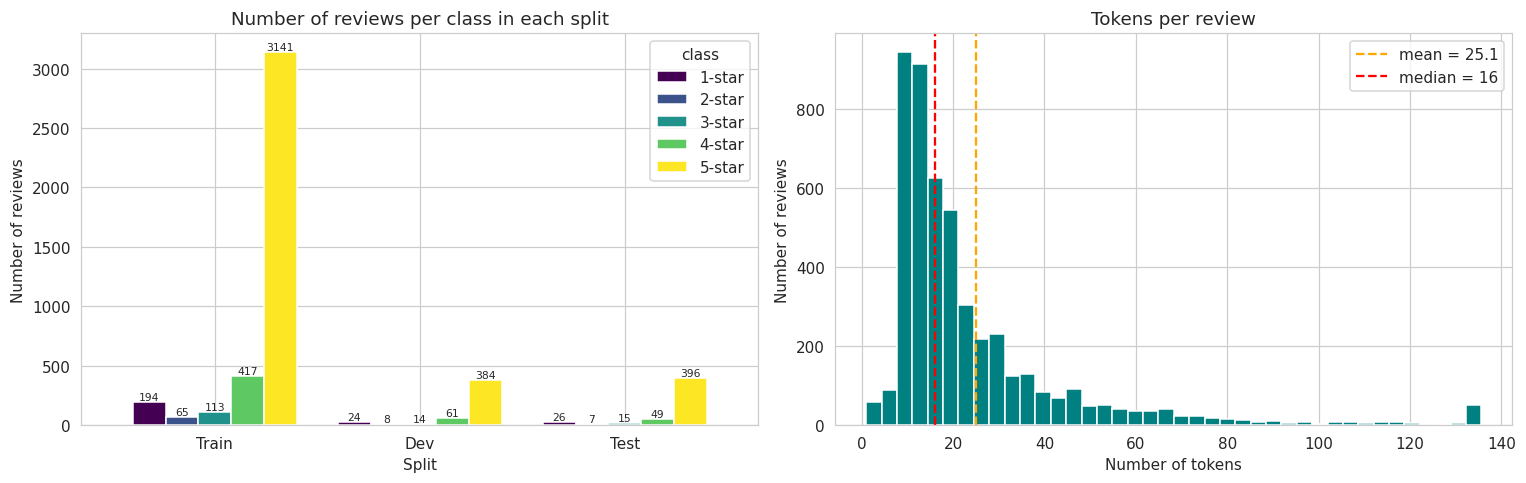

In [10]:
all_parts = [("Train", train_df), ("Dev", dev_df), ("Test", test_df), ("All", df)]

# (1) Number of reviews of each class in train / dev / test (required by the handout)
count_rows = []
for name, part in all_parts:
    counts = part["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
    count_rows.append({"Split": name, "Samples": len(part), **{CLASS_NAMES[i]: int(counts[i]) for i in range(NUM_CLASSES)}})
class_count_df = pd.DataFrame(count_rows).set_index("Split")
print("Number of reviews of each class:")
display(class_count_df)

print("\nPercentage of each class within a split:")
display((class_count_df[CLASS_NAMES].div(class_count_df["Samples"], axis=0) * 100).round(2))

# (2) Token statistics per split (same as in HW1)
rows = []
for name, part in all_parts:
    lens = part["tokens"].str.len()
    rows.append({"Split": name, "min_tokens": int(lens.min()), "avg_tokens": round(lens.mean(), 2),
                 "median_tokens": int(lens.median()), "max_tokens": int(lens.max())})
print("\nTokens per review (after preprocessing):")
display(pd.DataFrame(rows).set_index("Split"))

all_tokens = [t for toks in df["tokens"] for t in toks]
print(f"\nTotal tokens: {len(all_tokens):,} | Vocabulary size (distinct tokens): {len(set(all_tokens)):,}\n\n")

# (3) visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
class_count_df.loc[["Train", "Dev", "Test"], CLASS_NAMES].plot(kind="bar", ax=axes[0], colormap="viridis", width=0.8)
for c in axes[0].containers: axes[0].bar_label(c, fontsize=7)
axes[0].set_title("Number of reviews per class in each split");
axes[0].set_ylabel("Number of reviews")
axes[0].tick_params(axis="x", rotation=0);
axes[0].legend(title="class")

lens_all = df["tokens"].str.len()                      # Clipped at the 99th percentile so the long tail does not squash the plot
axes[1].hist(lens_all.clip(upper=lens_all.quantile(0.99)), bins=40, color="teal")
axes[1].axvline(lens_all.mean(), color="orange", ls="--", label=f"mean = {lens_all.mean():.1f}")
axes[1].axvline(lens_all.median(), color="red", ls="--", label=f"median = {lens_all.median():.0f}")
axes[1].set_title("Tokens per review");
axes[1].set_xlabel("Number of tokens");
axes[1].set_ylabel("Number of reviews")
axes[1].legend()
plt.tight_layout(); plt.show()

### Data statistics - what they mean for the models
* **Strong class imbalance.** About 80 % of all reviews are 5-star, while 1-, 2- and 3-star reviews are only about 5 %, 1.6 % and 2.9 %. Therefore a classifier that always answers "5 stars" is therefore already ~80 % accurate, so **accuracy alone is misleading** and **macro-averaged metrics** (every class counts equally) are used for model selection and reporting.
* **Very few examples in the minority classes.** The dev and test sets contain only roughly 7-15 reviews each of the 2-star and 3-star classes, so the per-class numbers for these classes are volatile (one review changes recall a lot).
* **Short texts.** The median review has only about 16 tokens, so a maximum length of about the 95th percentile (computed in the next section) loses little information and keeps batches small.

# 2. Shared building blocks for both neural models

**a) Vocabulary and encoding.
- ** Each word is mapped to an integer id.
- Id `0` is the padding token `<pad>`, id `1` is `<unk>` (words not in the vocabulary).
- The vocabulary is built from the **training set only**, so no information leaks from dev/test.
- `min_freq` removes very rare words.

In [11]:
PAD, UNK = "<pad>", "<unk>"
PAD_IDX, UNK_IDX = 0, 1

def build_vocab(token_lists, min_freq=1):
    """word -> integer id, built from the training reviews only (most frequent words get the smallest ids)."""
    freq = {}
    for toks in token_lists:
        for t in toks:
            freq[t] = freq.get(t, 0) + 1
    words = [w for w, c in sorted(freq.items(), key=lambda kv: (-kv[1], kv[0])) if c >= min_freq]
    vocab = {PAD: PAD_IDX, UNK: UNK_IDX}
    for w in words:
        vocab[w] = len(vocab)
    return vocab

def encode(tokens, vocab, max_len):
    """list of tokens -> list of ids (unknown words -> <unk>, reviews longer than max_len are truncated)."""
    return [vocab.get(t, UNK_IDX) for t in tokens[:max_len]]

# Maximum review length = 95th percentile of the training lengths (the median is only ~16 tokens)
MAX_LEN = int(np.percentile(train_df["tokens"].str.len(), 95))
print("MAX_LEN (95th percentile of training review lengths):", MAX_LEN)

train_tokens = train_df["tokens"].tolist()
y_train, y_dev, y_test = train_df["label"].values, dev_df["label"].values, test_df["label"].values

MAX_LEN (95th percentile of training review lengths): 67


**b) Dataset and batching.**
- `ReviewDataset` stores the encoded reviews and labels.
- `make_collate` builds a function that pads all reviews of a mini-batch to the same length (the longest one in the batch, but at least `min_len`, which the CNN needs because its widest filter spans 5 words) and also returns the true lengths (the LSTM uses them to ignore the padding).

In [12]:
class ReviewDataset(Dataset):
    """Holds the integer encoded reviews and their class labels."""
    def __init__(self, token_lists, labels, vocab, max_len):
        self.ids = [encode(t, vocab, max_len) for t in token_lists]
        self.labels = [int(l) for l in labels]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.ids[i], self.labels[i]

def make_collate(min_len=1):
    """Returns a collate function: pads a list of (ids, label) pairs into tensors (padded, lengths, labels)."""
    def collate(batch):
        seqs, labels = zip(*batch)
        lengths = torch.tensor([len(s) for s in seqs], dtype=torch.long)
        L = max(int(lengths.max()), min_len)                         # pad to the longest review of the batch
        padded = torch.full((len(seqs), L), PAD_IDX, dtype=torch.long)
        for i, s in enumerate(seqs):
            padded[i, :len(s)] = torch.tensor(s, dtype=torch.long)
        return padded, lengths, torch.tensor(labels, dtype=torch.long)
    return collate

def make_loaders(vocab, batch_size, min_len=1):
    """Train / dev / test DataLoaders. Only the training loader is shuffled (with a seeded generator)."""
    collate = make_collate(min_len)
    g = torch.Generator(); g.manual_seed(SEED)
    sets = [ReviewDataset(d["tokens"].tolist(), d["label"].values, vocab, MAX_LEN) for d in (train_df, dev_df, test_df)]
    train_loader = DataLoader(sets[0], batch_size=batch_size, shuffle=True, collate_fn=collate, generator=g)
    dev_loader   = DataLoader(sets[1], batch_size=128, shuffle=False, collate_fn=collate)
    test_loader  = DataLoader(sets[2], batch_size=128, shuffle=False, collate_fn=collate)
    return train_loader, dev_loader, test_loader

**c) Class-weighted loss.**
- Because ~80 % of the reviews are 5-star, an unweighted loss would let the model ignore the rare classes.
- The loss of each class is multiplied by a weight proportional to `(N / (K * n_c)) ** 0.5` (an *softened* inverse frequency, normalised to mean 1): rare classes count more, but not so much that training becomes unstable. The weights are computed from the **training labels only** and used for both models.

In [13]:
train_class_counts = np.bincount(y_train, minlength=NUM_CLASSES)
class_weights = (len(y_train) / (NUM_CLASSES * train_class_counts)) ** 0.5     # Softened inverse-frequency weights
class_weights = class_weights / class_weights.mean()                          # Normalise to mean 1
class_weights_t = torch.tensor(class_weights, dtype=torch.float32, device=device)
print(pd.DataFrame({"class": CLASS_NAMES, "train_count": train_class_counts, "loss_weight": class_weights.round(3)}).to_string(index=False))

criterion = nn.CrossEntropyLoss(weight=class_weights_t)   # Softmax + Negative log-likelihood along with class weights

 class  train_count  loss_weight
1-star          194        1.006
2-star           65        1.739
3-star          113        1.319
4-star          417        0.686
5-star         3141        0.250


**d) Evaluation metrics (multi-class).**
- `evaluate_multiclass` turns the predicted class probabilities into hard predictions (`argmax`) and reports **accuracy**, **macro** precision / recall / F1 score, **weighted** F1 and the one-vs-rest **macro AUC**.
- Macro-F1 is the main model-selection metric because it gives every class the same importance.

In [14]:
def evaluate_multiclass(y_true, y_prob):
    """All metrics from true labels (n,) and predicted class probabilities (n, 5)."""
    y_prob = np.asarray(y_prob, dtype=np.float64)
    y_prob = y_prob / y_prob.sum(axis=1, keepdims=True)            # Make sure each row sums to exactly 1
    y_pred = y_prob.argmax(axis=1)
    try:
        auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro", labels=list(range(NUM_CLASSES)))
    except ValueError:
        auc = float("nan")
    return {"accuracy":        accuracy_score(y_true, y_pred),
            "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "macro_recall":    recall_score(y_true, y_pred, average="macro", zero_division=0),
            "macro_f1":        f1_score(y_true, y_pred, average="macro", zero_division=0),
            "weighted_f1":     f1_score(y_true, y_pred, average="weighted", zero_division=0),
            "auc_ovr_macro":   auc}

# Reference point: the "always 5-star" classifier on the test set
majority_class = int(np.bincount(y_train).argmax())
majority_prob = np.zeros((len(y_test), NUM_CLASSES)); majority_prob[:, majority_class] = 1.0
majority_baseline = evaluate_multiclass(y_test, majority_prob)
majority_baseline["auc_ovr_macro"] = 0.5          # A constant score has no ranking ability
print(f"Majority class: {CLASS_NAMES[majority_class]} | share in the test set: {(y_test == majority_class).mean():.3f}")
print("Majority-class baseline on test:", {k: round(v, 4) for k, v in majority_baseline.items()})

Majority class: 5-star | share in the test set: 0.803
Majority-class baseline on test: {'accuracy': 0.8032, 'macro_precision': 0.1606, 'macro_recall': 0.2, 'macro_f1': 0.1782, 'weighted_f1': 0.7156, 'auc_ovr_macro': 0.5}


**e) Generic training / evaluation loop.**

In [15]:
def run_epoch(model, loader, optimizer=None, clip=None):
    """One epoch. optimizer given -> training mode (weights updated); otherwise evaluation mode.
    Returns (mean loss, true labels, predicted probabilities)."""
    training = optimizer is not None
    model.train(training)                                   # Enables/Disables dropout
    total_loss, n, ys, probs = 0.0, 0, [], []
    with torch.set_grad_enabled(training):                  # No gradients needed for evaluation
        for x, lengths, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x, lengths)                      # Forward pass -> (batch, 5) scores
            loss = criterion(logits, y)                     # class-weighted cross-entropy
            if training:
                optimizer.zero_grad()                       # Make old gradients zero
                loss.backward()                             # Backpropagation
                if clip is not None:                        # Gradient clipping
                    nn.utils.clip_grad_norm_(model.parameters(), clip)
                optimizer.step()                            # Parameter update
            total_loss += loss.item() * len(y); n += len(y)
            ys.append(y.cpu().numpy()); probs.append(torch.softmax(logits, dim=1).detach().cpu().numpy())
    return total_loss / n, np.concatenate(ys), np.concatenate(probs)

def train_model(model, train_loader, dev_loader, optimizer, epochs, patience, clip=None, name="model"):
    """Train for up to `epochs`; keep the best epoch by validation macro-F1 (ties: validation accuracy)."""
    history, best_key, best_epoch, best_state = [], (-1.0, -1.0), 0, None
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, ytr, ptr = run_epoch(model, train_loader, optimizer, clip)
        va_loss, yva, pva = run_epoch(model, dev_loader)
        m = evaluate_multiclass(yva, pva)
        history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss,
                        "train_acc": accuracy_score(ytr, ptr.argmax(1)),         # Running accuracy (dropout on)
                        "val_acc": m["accuracy"], "val_macro_f1": m["macro_f1"], "val_auc": m["auc_ovr_macro"]})
        key = (m["macro_f1"], m["accuracy"])                                     # Model selection criterion
        if key > best_key:                                                       # New best epoch
            best_key, best_epoch, best_state = key, epoch, copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {epoch:3d} | train loss {tr_loss:.4f} | val loss {va_loss:.4f} | "
              f"val acc {m['accuracy']:.4f} | val macro-F1 {m['macro_f1']:.4f} | {time.time()-t0:.1f}s"
              + ("  <-- best" if epoch == best_epoch else ""))
        if epoch - best_epoch >= patience:                                       # Early stopping
            print(f"[{name}] early stopping: no validation macro-F1 improvement for {patience} epochs.")
            break
    model.load_state_dict(best_state)                                            # Restore the best weights
    return model, pd.DataFrame(history), best_epoch

def plot_history(hist, best_epoch, title):
    """Learning curves: losses (left) and validation metrics (right); dashed line = selected epoch."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(hist["epoch"], hist["train_loss"], label="training loss")
    axes[0].plot(hist["epoch"], hist["val_loss"], label="validation loss")
    axes[0].axvline(best_epoch, color="gray", ls="--", label=f"selected epoch ({best_epoch})")
    axes[0].set_xlabel("Epoch");
    axes[0].set_ylabel("Class-weighted cross-entropy");
    axes[0].set_title(f"{title}: loss");
    axes[0].legend()
    axes[1].plot(hist["epoch"], hist["val_macro_f1"], label="validation macro-F1")
    axes[1].plot(hist["epoch"], hist["val_acc"], label="validation accuracy")
    axes[1].plot(hist["epoch"], hist["train_acc"], label="training accuracy (running)", alpha=0.6)
    axes[1].axvline(best_epoch, color="gray", ls="--")
    axes[1].set_xlabel("Epoch");
    axes[1].set_title(f"{title}: metrics");
    axes[1].legend()
    plt.tight_layout();
    plt.show()

def predict(model, loader):
    """Class probabilities of a trained model on a loader (evaluation mode)."""
    _, y, p = run_epoch(model, loader)
    return y, p

# 3. Sentiment analysis with an RNN (2-layer LSTM)
Requirements of the handout and how they are met:

| Requirement | Implementation |
|---|---|
| 2-layer LSTM or GRU (PyTorch package) | `nn.LSTM(..., num_layers=2)` |
| SGD optimiser | `torch.optim.SGD` (with momentum 0.9) |
| Word embeddings initialised randomly and learned during training | `nn.Embedding` with PyTorch's default random initialisation, trainable |
| Other parameters are free | embedding 100, hidden 128, dropout 0.3, batch 32, lr 0.05, gradient clipping 1.0 |

**Architecture.** `review ids -> random embedding (100-d) -> 2-layer LSTM (128 hidden units) -> hidden state of the last real word of the top layer -> dropout -> linear layer -> 5 class scores (softmax inside the loss)`. `pack_padded_sequence` makes the LSTM skip the padding so the final hidden state really belongs to the last word of each review. Gradient clipping (lecture "More on RNNs") protects against exploding gradients.

In [16]:
class LSTMClassifier(nn.Module):
    """Embedding -> 2-layer LSTM -> dropout -> linear."""
    def __init__(self, vocab_size, emb_dim, hidden_dim, n_layers, n_classes, dropout):
        super().__init__()
        # Randomly initialised embeddings (N(0,1) by default); the padding row stays zero
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=n_layers, batch_first=True,
                            dropout=dropout)                   # Dropout between the two LSTM layers
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, lengths):
        emb = self.dropout(self.embedding(x))                  # (batch, seq, emb_dim)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)                        # h_n: (n_layers, batch, hidden)
        return self.fc(self.dropout(h_n[-1]))                  # last layer's final hidden state -> class scores


# Hyper-parameters (free choice according to the handout)
RNN_CFG = dict(emb_dim=100, hidden_dim=128, n_layers=2, dropout=0.3,
               batch_size=32, lr=0.05, momentum=0.9, clip=1.0, epochs=40, patience=10, min_freq=2)

vocab_rnn = build_vocab(train_tokens, min_freq=RNN_CFG["min_freq"])       # Words seen at least twice in training
print(f"RNN vocabulary size: {len(vocab_rnn)} (words with frequency >= {RNN_CFG['min_freq']} + <pad> + <unk>)")

set_seed()
rnn_train_loader, rnn_dev_loader, rnn_test_loader = make_loaders(vocab_rnn, RNN_CFG["batch_size"])
rnn_model = LSTMClassifier(len(vocab_rnn), RNN_CFG["emb_dim"], RNN_CFG["hidden_dim"], RNN_CFG["n_layers"],
                           NUM_CLASSES, RNN_CFG["dropout"]).to(device)
rnn_optimizer = torch.optim.SGD(rnn_model.parameters(), lr=RNN_CFG["lr"], momentum=RNN_CFG["momentum"])   # SGD (required)
print(rnn_model)
print("Trainable parameters:", sum(p.numel() for p in rnn_model.parameters() if p.requires_grad))

RNN vocabulary size: 3617 (words with frequency >= 2 + <pad> + <unk>)
LSTMClassifier(
  (embedding): Embedding(3617, 100, padding_idx=0)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=5, bias=True)
)
Trainable parameters: 612201


**Training.** The LSTM is trained on the training set; after every epoch it is scored on the validation set and the epoch with the best validation macro-F1 is kept.

[LSTM] epoch   1 | train loss 1.3291 | val loss 1.3305 | val acc 0.7821 | val macro-F1 0.1755 | 2.8s  <-- best
[LSTM] epoch   2 | train loss 1.2839 | val loss 1.2745 | val acc 0.7597 | val macro-F1 0.2209 | 1.3s  <-- best
[LSTM] epoch   3 | train loss 1.2126 | val loss 1.1939 | val acc 0.7597 | val macro-F1 0.2165 | 1.3s
[LSTM] epoch   4 | train loss 1.1596 | val loss 1.1507 | val acc 0.7597 | val macro-F1 0.2559 | 1.2s  <-- best
[LSTM] epoch   5 | train loss 1.0823 | val loss 1.1585 | val acc 0.7739 | val macro-F1 0.2592 | 1.2s  <-- best
[LSTM] epoch   6 | train loss 1.0040 | val loss 1.1627 | val acc 0.7719 | val macro-F1 0.2952 | 1.3s  <-- best
[LSTM] epoch   7 | train loss 0.9815 | val loss 1.1736 | val acc 0.7678 | val macro-F1 0.2825 | 1.3s
[LSTM] epoch   8 | train loss 0.9317 | val loss 1.1749 | val acc 0.7760 | val macro-F1 0.3082 | 1.3s  <-- best
[LSTM] epoch   9 | train loss 0.8596 | val loss 1.2550 | val acc 0.7556 | val macro-F1 0.2761 | 1.2s
[LSTM] epoch  10 | train loss 0

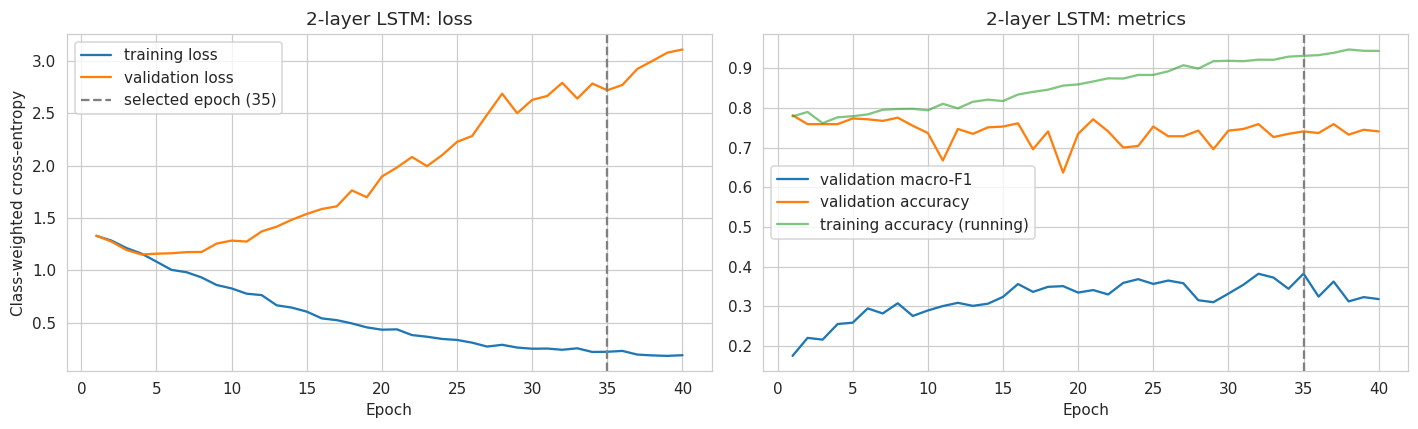

In [17]:
rnn_model, rnn_hist, rnn_best_epoch = train_model(rnn_model, rnn_train_loader, rnn_dev_loader, rnn_optimizer,
                                                  epochs=RNN_CFG["epochs"], patience=RNN_CFG["patience"],
                                                  clip=RNN_CFG["clip"], name="LSTM")
print(f"\nSelected LSTM epoch: {rnn_best_epoch}")
plot_history(rnn_hist, rnn_best_epoch, "2-layer LSTM")

# 4. Sentiment analysis with a CNN

**a) Load GloVe** with the same `load_embedding_model()` function used in HW1 (`glove-wiki-gigaword-200`: 400,000 words, 200 dimensions).

In [18]:
def load_embedding_model():
    """ Load GloVe Vectors
        Return:
            wv_from_bin: All 400000 embeddings, each lengh 200
    """

    %pip install gensim
    import gensim.downloader as api
    wv_from_bin = api.load("glove-wiki-gigaword-200")
    print("Loaded vocab size %i" % len(list(wv_from_bin.index_to_key)))
    return wv_from_bin

# -----------------------------------
# Run Cell to Load Word Vectors
# Note: This will take a couple minutes
# -----------------------------------
wv_from_bin = load_embedding_model()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 132.5 MB/s  0:00:00
[==================================================] 100.0% 252.1/252.1MB downloaded
Loaded vocab size 400000


**b) Build the CNN vocabulary and the embedding matrix.** The vocabulary comes from the training set (every word, `min_freq=1`, because GloVe already knows many rare words). Row *i* of `emb_matrix` is the GloVe vector of word *i*. Words that GloVe does not contain (typos, brand names, `<unk>`) get a small random vector, and `<pad>` stays all-zero. The whole matrix is **trainable**, so GloVe is fine-tuned.

In [19]:
vocab_cnn = build_vocab(train_tokens, min_freq=1)
EMB_DIM = wv_from_bin.vector_size                                   # 200
rng = np.random.RandomState(SEED)

emb_matrix = np.zeros((len(vocab_cnn), EMB_DIM), dtype=np.float32)  # row 0 (<pad>) stays zero
found = 0
for word, idx in vocab_cnn.items():
    if word == PAD:
        continue
    if word in wv_from_bin.key_to_index:                            # Word known to GloVe -> pre-trained vector
        emb_matrix[idx] = wv_from_bin[word]; found += 1
    else:                                                           # Unknown word / <unk> -> small random vector
        emb_matrix[idx] = rng.normal(0, 0.1, EMB_DIM)

print(f"CNN vocabulary size: {len(vocab_cnn)} | words initialised from GloVe: {found} ({found/(len(vocab_cnn)-1):.1%}) "
      f"| Randomly initialised: {len(vocab_cnn)-1-found}")
print("Embedding matrix shape:", emb_matrix.shape)

CNN vocabulary size: 6747 | words initialised from GloVe: 5910 (87.6%) | Randomly initialised: 836
Embedding matrix shape: (6747, 200)


**c) CNN architecture** (single-layer CNN for sentence classification, Kim 2014, as in the lecture "CNN, Tokenization"):

`review ids -> GloVe embedding (200-d, trainable) -> three parallel 1-D convolutions with filter widths 3, 4, 5 (100 filters each, i.e. detectors of 3-/4-/5-word phrases) -> ReLU -> max-over-time pooling -> concatenate (300 features) -> dropout -> linear layer -> 5 class scores`

Each filter slides over every window of consecutive words; max pooling keeps the strongest match anywhere in the review, so the model finds sentiment-bearing phrases regardless of their position. Reviews are padded to at least 5 tokens so that the widest filter always fits.

In [20]:
class TextCNN(nn.Module):
    """Embedding (GloVe, trainable) -> parallel Conv1d -> ReLU -> max-over-time -> dropout -> linear."""
    def __init__(self, emb_matrix, n_classes, kernel_sizes=(3, 4, 5), n_filters=100, dropout=0.5):
        super().__init__()
        # Initialise with GloVe; freeze=False -> The embeddings are UPDATED during training (handout requirement)
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(emb_matrix, dtype=torch.float32),
                                                      freeze=False, padding_idx=PAD_IDX)
        emb_dim = emb_matrix.shape[1]
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, n_filters, k) for k in kernel_sizes])   # One conv per filter width
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(n_filters * len(kernel_sizes), n_classes)

    def forward(self, x, lengths=None):                         # `lengths` is unused (kept so both models share a loop)
        e = self.embedding(x).transpose(1, 2)
        feats = [F.relu(conv(e)).max(dim=2).values for conv in self.convs]   # max-over-time pooling -> (batch, n_filters)
        return self.fc(self.dropout(torch.cat(feats, dim=1)))   # Concat -> Dropout -> class scores

# Hyper-parameters
CNN_CFG = dict(kernel_sizes=(3, 4, 5), n_filters=100, dropout=0.5,
               batch_size=20,                       # Mini-batch of size 20
               lr=0.02, momentum=0.9, epochs=40, patience=10)

set_seed()
cnn_train_loader, cnn_dev_loader, cnn_test_loader = make_loaders(vocab_cnn, CNN_CFG["batch_size"],
                                                                 min_len=max(CNN_CFG["kernel_sizes"]))
cnn_model = TextCNN(emb_matrix, NUM_CLASSES, CNN_CFG["kernel_sizes"], CNN_CFG["n_filters"], CNN_CFG["dropout"]).to(device)

# Mini-batch gradient descent: every update uses the gradient of one mini-batch of 20 reviews
cnn_optimizer = torch.optim.SGD(cnn_model.parameters(), lr=CNN_CFG["lr"], momentum=CNN_CFG["momentum"])
print(cnn_model)
print("Trainable parameters:", sum(p.numel() for p in cnn_model.parameters() if p.requires_grad))
print("Mini-batch size of the training loader:", cnn_train_loader.batch_size)

TextCNN(
  (embedding): Embedding(6747, 200, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(200, 100, kernel_size=(3,), stride=(1,))
    (1): Conv1d(200, 100, kernel_size=(4,), stride=(1,))
    (2): Conv1d(200, 100, kernel_size=(5,), stride=(1,))
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=300, out_features=5, bias=True)
)
Trainable parameters: 1591205
Mini-batch size of the training loader: 20


**d) Training.** Same procedure as for the LSTM: validate after each epoch and keep the epoch with the best validation macro-F1.

[CNN] epoch   1 | train loss 1.3819 | val loss 1.1915 | val acc 0.7597 | val macro-F1 0.2669 | 1.5s  <-- best
[CNN] epoch   2 | train loss 1.1678 | val loss 1.2689 | val acc 0.7475 | val macro-F1 0.2122 | 0.7s
[CNN] epoch   3 | train loss 1.1036 | val loss 1.2596 | val acc 0.7637 | val macro-F1 0.2139 | 0.8s
[CNN] epoch   4 | train loss 1.0429 | val loss 1.2796 | val acc 0.7495 | val macro-F1 0.3059 | 0.7s  <-- best
[CNN] epoch   5 | train loss 0.9245 | val loss 1.2160 | val acc 0.7434 | val macro-F1 0.3271 | 0.7s  <-- best
[CNN] epoch   6 | train loss 0.8578 | val loss 1.2675 | val acc 0.7576 | val macro-F1 0.2612 | 0.7s
[CNN] epoch   7 | train loss 0.7756 | val loss 1.4052 | val acc 0.7699 | val macro-F1 0.2853 | 0.7s
[CNN] epoch   8 | train loss 0.6823 | val loss 1.5754 | val acc 0.7760 | val macro-F1 0.2835 | 0.7s
[CNN] epoch   9 | train loss 0.6821 | val loss 1.4509 | val acc 0.7699 | val macro-F1 0.2995 | 0.7s
[CNN] epoch  10 | train loss 0.6187 | val loss 1.6591 | val acc 0.7637

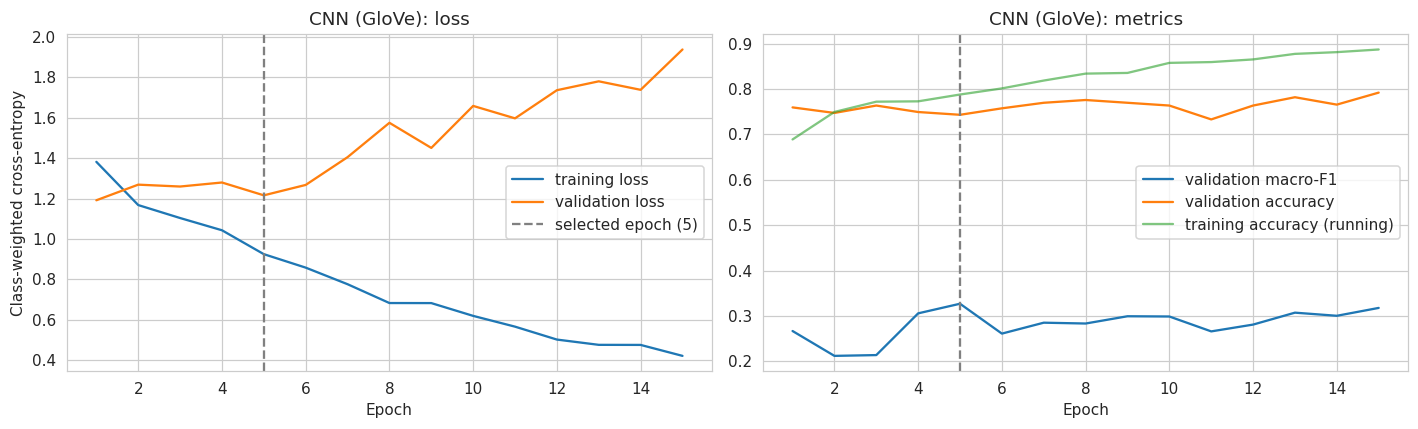

In [21]:
cnn_model, cnn_hist, cnn_best_epoch = train_model(cnn_model, cnn_train_loader, cnn_dev_loader, cnn_optimizer,
                                                  epochs=CNN_CFG["epochs"], patience=CNN_CFG["patience"],
                                                  clip=None, name="CNN")
print(f"\nSelected CNN epoch: {cnn_best_epoch}")
plot_history(cnn_hist, cnn_best_epoch, "CNN (GloVe)")

# 5. Evaluation

## 1) Metrics
Accuracy, macro precision / recall / F1, weighted F1 and one-vs-rest macro AUC, computed with `scikit-learn`. A per class report, confusion matrices and ROC curves follow. The "always 5-star" baseline is included as a reference.

In [22]:
y_test_true, p_test_rnn = predict(rnn_model, rnn_test_loader)
y_test_true2, p_test_cnn = predict(cnn_model, cnn_test_loader)
assert (y_test_true == y_test_true2).all() and (y_test_true == y_test).all()     # Both loaders give the same, unshuffled test order

res = pd.DataFrame({"Majority baseline (always 5-star)": majority_baseline,
                    "LSTM (2-layer, random emb., SGD)": evaluate_multiclass(y_test, p_test_rnn),
                    "CNN (GloVe emb., mini-batch 20)":  evaluate_multiclass(y_test, p_test_cnn)}).T
res.columns = ["Accuracy", "Macro precision", "Macro recall", "Macro F1", "Weighted F1", "AUC (OvR macro)"]
print(f"TEST SET RESULTS (n = {len(y_test)}; class counts {np.bincount(y_test, minlength=NUM_CLASSES).tolist()} for 1..5 stars)")
display(res.round(4))

for name, p in [("LSTM", p_test_rnn), ("CNN", p_test_cnn)]:
    print(f"\n===== {name}: per-class report (test) =====")
    print(classification_report(y_test, p.argmax(1), labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES, digits=4, zero_division=0))

TEST SET RESULTS (n = 493; class counts [26, 7, 15, 49, 396] for 1..5 stars)


,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,AUC (OvR macro)
Majority baseline (always 5-star),0.8032,0.1606,0.2000,0.1782,0.7156,0.5000
"LSTM (2-layer, random emb., SGD)",0.7302,0.2670,0.2715,0.2692,0.7281,0.6694
"CNN (GloVe emb., mini-batch 20)",0.7404,0.2963,0.2885,0.2919,0.7300,0.6714



===== LSTM: per-class report (test) =====
              precision    recall  f1-score   support

      1-star     0.2857    0.3077    0.2963        26
      2-star     0.0000    0.0000    0.0000         7
      3-star     0.0000    0.0000    0.0000        15
      4-star     0.1875    0.1837    0.1856        49
      5-star     0.8618    0.8662    0.8640       396

    accuracy                         0.7302       493
   macro avg     0.2670    0.2715    0.2692       493
weighted avg     0.7259    0.7302    0.7281       493


===== CNN: per-class report (test) =====
              precision    recall  f1-score   support

      1-star     0.5217    0.4615    0.4898        26
      2-star     0.0000    0.0000    0.0000         7
      3-star     0.0000    0.0000    0.0000        15
      4-star     0.1111    0.1020    0.1064        49
      5-star     0.8488    0.8788    0.8635       396

    accuracy                         0.7404       493
   macro avg     0.2963    0.2885    0.2919   

**Visualisations:** (top) confusion matrices of the two models on the test set (rows = true class, columns = predicted class); (middle) one-vs-rest ROC curve of every class for each model; (bottom) bar chart of the headline metrics.

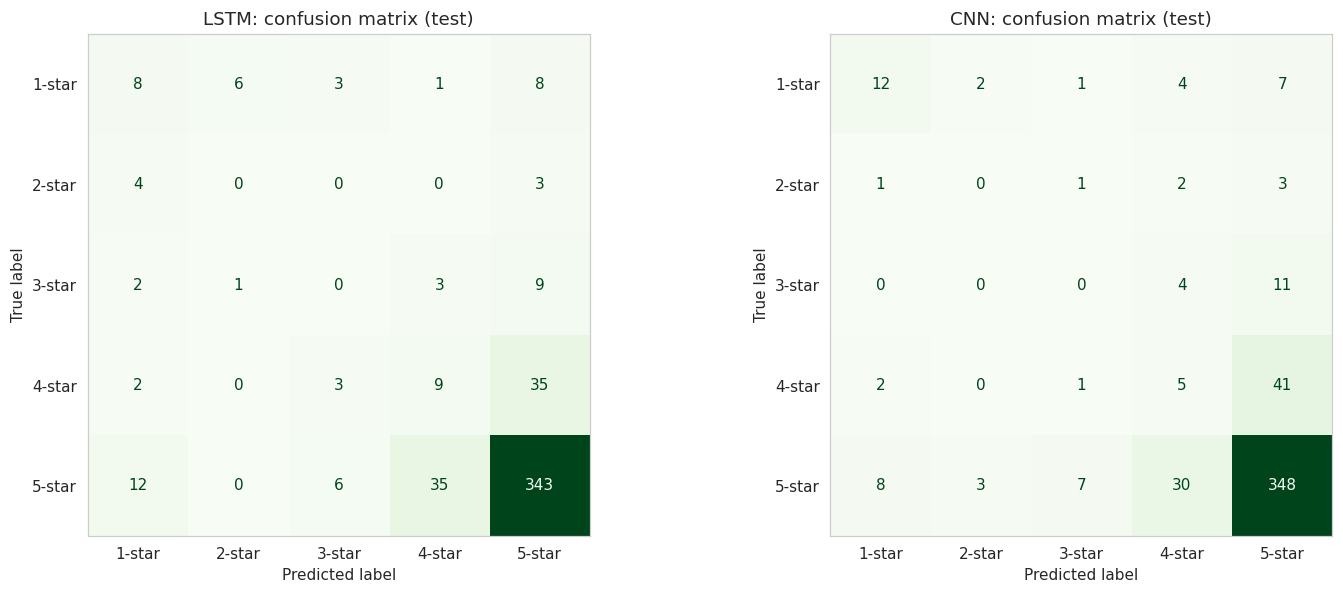

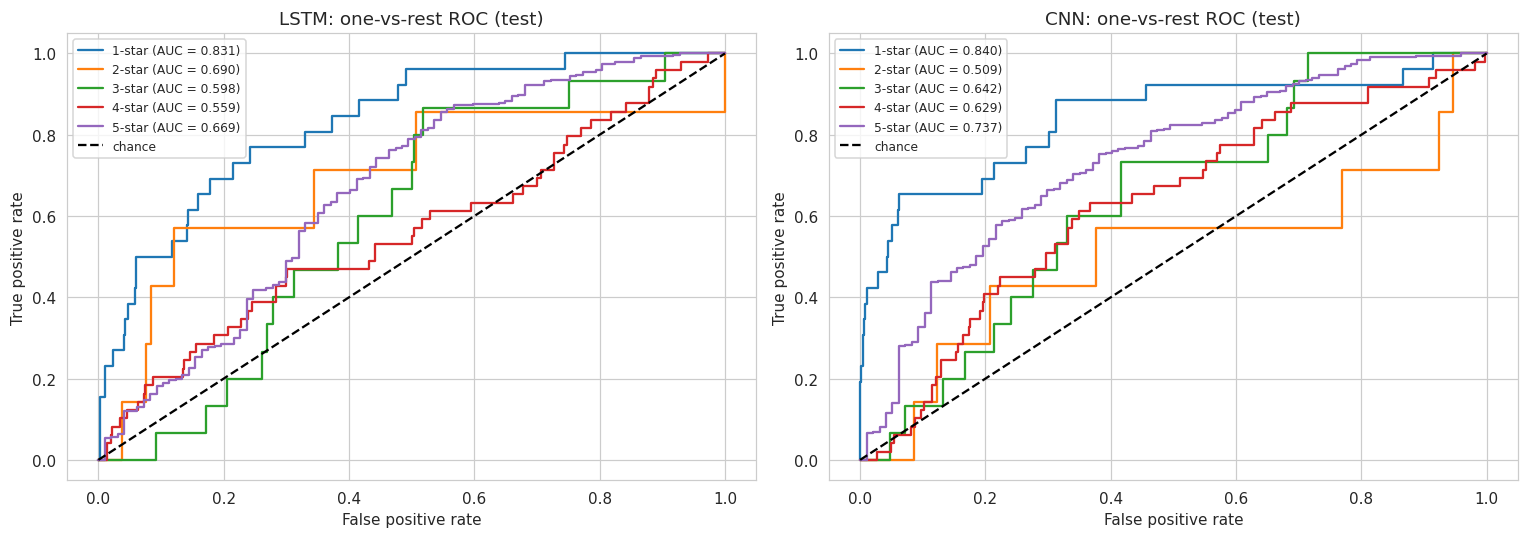

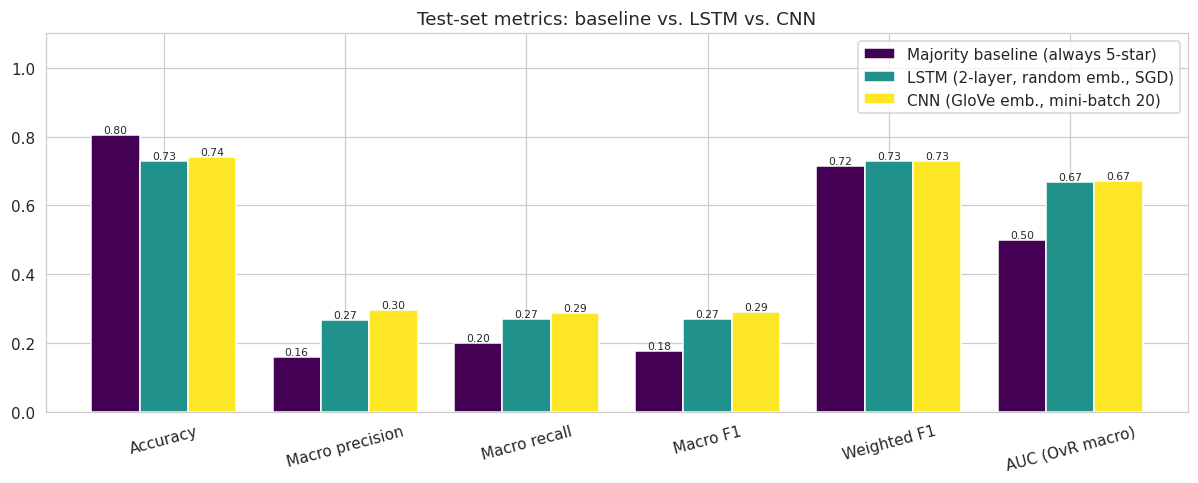

In [23]:
# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, p) in zip(axes, [("LSTM", p_test_rnn), ("CNN", p_test_cnn)]):
    cm = confusion_matrix(y_test, p.argmax(1), labels=list(range(NUM_CLASSES)))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(f"{name}: confusion matrix (test)"); ax.grid(False)
plt.tight_layout(); plt.show()

# One-vs-rest ROC curves per class
y_bin = label_binarize(y_test, classes=list(range(NUM_CLASSES)))                 # (n, 5) One-hot true labels
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, p) in zip(axes, [("LSTM", p_test_rnn), ("CNN", p_test_cnn)]):
    for c in range(NUM_CLASSES):
        if y_bin[:, c].sum() == 0:      # Class absent from the test set -> ROC undefined
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, c], p[:, c])
        ax.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} (AUC = {roc_auc_score(y_bin[:, c], p[:, c]):.3f})")
    ax.plot([0, 1], [0, 1], "k--", label="chance")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title(f"{name}: one-vs-rest ROC (test)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Bar chart of the headline metrics -
ax = res.T.plot(kind="bar", figsize=(11, 4.5), width=0.8, colormap="viridis")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
ax.set_ylim(0, 1.1); ax.set_title("Test-set metrics: baseline vs. LSTM vs. CNN"); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## 2) Comparison of the LSTM and the CNN

In [24]:
from IPython.display import Markdown, display

L, C, B = res.loc["LSTM (2-layer, random emb., SGD)"], res.loc["CNN (GloVe emb., mini-batch 20)"], res.loc["Majority baseline (always 5-star)"]
f1_rnn = f1_score(y_test, p_test_rnn.argmax(1), average=None, labels=list(range(NUM_CLASSES)), zero_division=0)
f1_cnn = f1_score(y_test, p_test_cnn.argmax(1), average=None, labels=list(range(NUM_CLASSES)), zero_division=0)

def winner(metric):
    return "CNN" if C[metric] > L[metric] else ("LSTM" if L[metric] > C[metric] else "tie")

better = "CNN" if C["Macro F1"] > L["Macro F1"] else "LSTM"       # Overall winner = macro-F1 (the model-selection metric)
cnn_wins_cls = [CLASS_NAMES[i] for i in range(NUM_CLASSES) if f1_cnn[i] > f1_rnn[i]]
rnn_wins_cls = [CLASS_NAMES[i] for i in range(NUM_CLASSES) if f1_rnn[i] > f1_cnn[i]]

txt = f"""
**Results on the test set (n = {len(y_test)}), exactly as returned by this run**

| Metric | Baseline | LSTM | CNN | Better |
|---|---:|---:|---:|---|
""" + "\n".join(f"| {m} | {B[m]:.4f} | {L[m]:.4f} | {C[m]:.4f} | {winner(m)} |" for m in res.columns) + f"""

"""
display(Markdown(txt))


**Results on the test set (n = 493), exactly as returned by this run**

| Metric | Baseline | LSTM | CNN | Better |
|---|---:|---:|---:|---|
| Accuracy | 0.8032 | 0.7302 | 0.7404 | CNN |
| Macro precision | 0.1606 | 0.2670 | 0.2963 | CNN |
| Macro recall | 0.2000 | 0.2715 | 0.2885 | CNN |
| Macro F1 | 0.1782 | 0.2692 | 0.2919 | CNN |
| Weighted F1 | 0.7156 | 0.7281 | 0.7300 | CNN |
| AUC (OvR macro) | 0.5000 | 0.6694 | 0.6714 | CNN |



## 3) Discussion: HW1 vs. HW2 and the best model


,Accuracy,Macro F1,AUC,Baseline accuracy,Accuracy - baseline,Macro-F1 baseline,Macro F1 - baseline
HW1 Logistic regression (binary),0.8808,0.6951,0.9116,0.9310,-0.0502,0.4821,0.2130
HW1 Neural network / MLP (binary),0.9498,0.7797,0.9053,0.9310,0.0188,0.4821,0.2976
HW2 LSTM (5-class),0.7302,0.2692,0.6694,0.8032,-0.0730,0.1782,0.0910
HW2 CNN (5-class),0.7404,0.2919,0.6714,0.8032,-0.0629,0.1782,0.1138


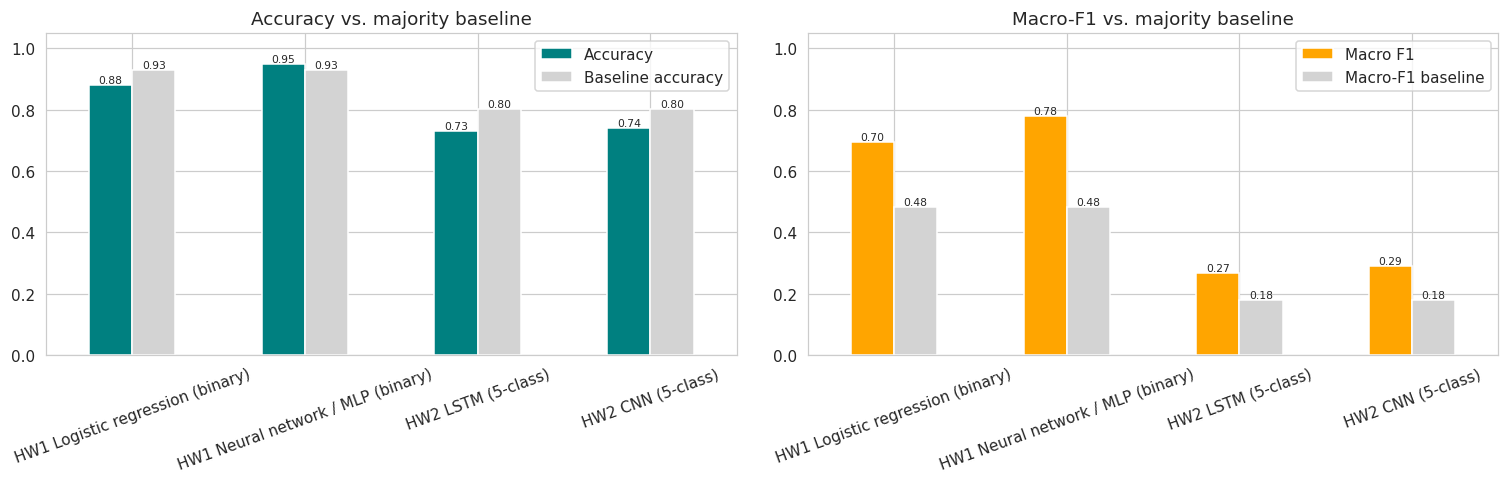

In [25]:
# HW1 test-set numbers (binary task) taken from the HW1 notebook output (logistic regression and MLP on averaged GloVe vectors)
HW1 = {"HW1 Logistic regression (binary)": {"Accuracy": 0.8808, "Macro F1": 0.6951, "AUC": 0.9116, "Baseline accuracy": 0.9310},
       "HW1 Neural network / MLP (binary)": {"Accuracy": 0.9498, "Macro F1": 0.7797, "AUC": 0.9053, "Baseline accuracy": 0.9310}}
HW2 = {"HW2 LSTM (5-class)": {"Accuracy": L["Accuracy"], "Macro F1": L["Macro F1"], "AUC": L["AUC (OvR macro)"], "Baseline accuracy": B["Accuracy"]},
       "HW2 CNN (5-class)":  {"Accuracy": C["Accuracy"], "Macro F1": C["Macro F1"], "AUC": C["AUC (OvR macro)"], "Baseline accuracy": B["Accuracy"]}}

cmp_df = pd.DataFrame({**HW1, **HW2}).T
cmp_df["Accuracy - baseline"] = cmp_df["Accuracy"] - cmp_df["Baseline accuracy"]
cmp_df["Macro-F1 baseline"] = [0.4821, 0.4821, f1_score(y_test, majority_prob.argmax(1), average="macro", zero_division=0),
                               f1_score(y_test, majority_prob.argmax(1), average="macro", zero_division=0)]
cmp_df["Macro F1 - baseline"] = cmp_df["Macro F1"] - cmp_df["Macro-F1 baseline"]
display(cmp_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cmp_df[["Accuracy", "Baseline accuracy"]].plot(kind="bar", ax=axes[0], color=["teal", "lightgray"])
axes[0].set_title("Accuracy vs. majority baseline"); axes[0].set_ylim(0, 1.05); axes[0].tick_params(axis="x", rotation=20)
cmp_df[["Macro F1", "Macro-F1 baseline"]].plot(kind="bar", ax=axes[1], color=["orange", "lightgray"])
axes[1].set_title("Macro-F1 vs. majority baseline"); axes[1].set_ylim(0, 1.05); axes[1].tick_params(axis="x", rotation=20)
for ax in axes:
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.show()

In [26]:
best_hw1 = "HW1 Neural network / MLP (binary)"                      # Best HW1 model (highest macro-F1 / accuracy in HW1)
best_hw2 = "HW2 CNN (5-class)" if better == "CNN" else "HW2 LSTM (5-class)"
bh1, bh2 = cmp_df.loc[best_hw1], cmp_df.loc[best_hw2]

if better == "CNN":
    reasons = """
* **Pre-trained knowledge.** The CNN starts from GloVe vectors learned on ~6 billion tokens, so words such as *great*, *terrible* or *refund* already have meaningful positions in the vector space. The LSTM has to learn its random embeddings from only ~3.9k training reviews, which is far too little for rare sentiment words.
* **Local n-gram detectors fit this data.** The reviews are short (median ~16 tokens) and the sentiment is carried by short phrases; the 3/4/5-word filters plus max-over-time pooling find the strongest sentiment phrase wherever it occurs. Also the LSTM has to squeeze the whole review into one final hidden state.
* **Optimisation.** The CNN has shorter gradient paths (no recurrence over time), so it trains more reliably with plain mini-batch SGD than a 2-layer LSTM, which is more sensitive to the learning rate and to vanishing/exploding gradients."""
else:
    reasons = """
* **Word order and context.** The LSTM reads the review sequentially, so its final hidden state can represent how earlier words modify later ones (e.g. a complaint followed by a positive conclusion), which a bag of fixed-width n-gram filters can only approximate.
* **Gated memory.** The forget/input/output gates of the LSTM let it keep sentiment-relevant information over the whole (short) review, while gradient clipping keeps the SGD training stable.
* **Even without pre-trained vectors,** the task-specific embeddings can adapt to this domain (electronics reviews), whereas the GloVe vectors come from encyclopaedic / news text; the CNN may also overfit more easily because its GloVe-based embedding matrix is large."""

txt = f"""
**Are there differences between HW1 and HW2?** Yes.
* **Task:** HW1 was binary (positive/negative) while HW2 is 5-class, which is more difficult because neighbouring classes (4 vs. 5 stars, 1 vs. 2 stars, and the neutral 3 stars) differ only slightly in wording, and the classes are very imbalanced.
* **Features and models:** HW1 used *averaged* GloVe vectors with logistic regression while an MLP; HW2 feeds the *word sequence* to an LSTM and a CNN.
* **Numbers:** the best HW1 model ({best_hw1}) reached accuracy of {bh1['Accuracy']:.4f} ({bh1['Accuracy - baseline']:+.4f} vs. its {bh1['Baseline accuracy']:.4f} baseline) and macro-F1 {bh1['Macro F1']:.4f};
  the best HW2 model ({best_hw2}) reached accuracy {bh2['Accuracy']:.4f} ({bh2['Accuracy - baseline']:+.4f} vs. its {bh2['Baseline accuracy']:.4f} baseline) and macro-F1 {bh2['Macro F1']:.4f}
  (macro-F1 gain over the baseline: HW1 {bh1['Macro F1 - baseline']:+.4f}, HW2 {bh2['Macro F1 - baseline']:+.4f}). The absolute values should not be compared one-to-one, since 5 classes make every metric harder to score high on and the baselines differ.

**Which model performs best?** Among the two HW2 models, the **{better}** has the higher macro-F1 (LSTM {L['Macro F1']:.4f}, CNN {C['Macro F1']:.4f}). Possible underlying reasons (based on my configuration):
{reasons}

"""
display(Markdown(txt))


**Are there differences between HW1 and HW2?** Yes.
* **Task:** HW1 was binary (positive/negative) while HW2 is 5-class, which is more difficult because neighbouring classes (4 vs. 5 stars, 1 vs. 2 stars, and the neutral 3 stars) differ only slightly in wording, and the classes are very imbalanced.
* **Features and models:** HW1 used *averaged* GloVe vectors with logistic regression while an MLP; HW2 feeds the *word sequence* to an LSTM and a CNN.
* **Numbers:** the best HW1 model (HW1 Neural network / MLP (binary)) reached accuracy of 0.9498 (+0.0188 vs. its 0.9310 baseline) and macro-F1 0.7797;
  the best HW2 model (HW2 CNN (5-class)) reached accuracy 0.7404 (-0.0629 vs. its 0.8032 baseline) and macro-F1 0.2919
  (macro-F1 gain over the baseline: HW1 +0.2976, HW2 +0.1138). The absolute values should not be compared one-to-one, since 5 classes make every metric harder to score high on and the baselines differ.

**Which model performs best?** Among the two HW2 models, the **CNN** has the higher macro-F1 (LSTM 0.2692, CNN 0.2919). Possible underlying reasons (based on my configuration):

* **Pre-trained knowledge.** The CNN starts from GloVe vectors learned on ~6 billion tokens, so words such as *great*, *terrible* or *refund* already have meaningful positions in the vector space. The LSTM has to learn its random embeddings from only ~3.9k training reviews, which is far too little for rare sentiment words.
* **Local n-gram detectors fit this data.** The reviews are short (median ~16 tokens) and the sentiment is carried by short phrases; the 3/4/5-word filters plus max-over-time pooling find the strongest sentiment phrase wherever it occurs. Also the LSTM has to squeeze the whole review into one final hidden state.
* **Optimisation.** The CNN has shorter gradient paths (no recurrence over time), so it trains more reliably with plain mini-batch SGD than a 2-layer LSTM, which is more sensitive to the learning rate and to vanishing/exploding gradients.



# 6. Self-reflection

| Question | Answer (provide the answer index) |
|---|---|
| **Q1:** Rate your performance | **5** |
| **Q2:** How much does your understanding of the concepts influence your performance? | **5** |
| **Q3:** How much does the design of the examples/questions influence your performance? | **4** |
| **Q4:** Primary factors influencing the relatability of the examples | **7** (prior knowledge about the context in the example) |


# 7. References and resources used
* Lecture slides: *Language Modeling (RNN)*, *More on RNNs* (vanishing gradients, LSTM/GRU, gradient clipping, multi-layer RNNs), *CNN, Tokenization* (1-D convolution for text, max-over-time pooling, single-layer CNN for sentence classification).
* Own HW1 notebook: data loading, preprocessing function, data split code and `load_embedding_model()` are re-used unchanged (the latter was taken from the HW1 handout).
* **Generative-AI disclosure:** Claude (Anthropic) was used to help draft the final results after careful understanding and to plot the graphs and necessary visualizations for my better understading. All the comments and the wording of the discussion cells were done by myself. I reviewed the code, ran it myself and checked that the discussion matches the numbers my run produced